# Linear buckling analysis of a cylinder under torsion

The cylinders Z11 and Z33 of Castro et al. (2014), two unsymmetric laminates
of `Quad4` elements, under torsion, with the boundary conditions CC2 of that
paper. The laminate of each element is oriented by a material direction along
the axis of the cylinder, see [Conventions](../conventions.rst). The torques
are compared with the pure-torsion intercepts of Fig. 13 of the paper, to
which the element converges within 0.7 %; the docstring of the test gives the
measured convergence (`tests/test_quad4_linear_buckling_cylinder_Nxy.py`).
The analysis is described in
[Linear buckling and natural frequencies](../eigenvalue_analyses.rst) and the
element in [Quad4: assumed transverse shear strains (MITC4)](../shell_quad4.rst);
the full references are at the end of the notebook.

In [1]:
import os
import sys

sys.path.insert(0, os.path.join('..', 'tests'))

import time
import numpy as np
import pytest
from numpy import isclose
from scipy.sparse import coo_matrix
from pyfe3d import DOF, DOUBLE, INT, Quad4, Quad4Data, Quad4Probe
from pyfe3d.shellprop_utils import laminated_plate
from pyfe3d.solver import linear_buckling
from test_quad4_linear_buckling_cylinder_Nxy import _cylindrical_transformation

import pyvista as pv

# NOTE static images of the PyVista figures, stored in the notebook
pv.set_jupyter_backend('static')

## What the test verifies, and against what

The geometry, $R = 250$ mm, $H = 510$ mm and the ply thickness 0.125 mm, and
the stacking sequences, from inwards to outwards, are those of Table 4 of
Castro et al. (2014, p. 307), the material Geier1997 that of their Table 3,
and the shear correction factor 5/6 that of their Sec. 6. The boundary
condition CC2 of their Table 1 (p. 304), $v = w = w_{,x} = 0$ at both edges
with the axial displacement $u$ free, is imposed in cylindrical coordinates;
one node is held axially to remove the rigid translation. The reference load
is a uniform shear resultant $N_{x\theta}$, given to each element with
`update_KG_given_stress`, which is the torque $T = -2 \pi R^2 N_{x\theta}$ of
Eq. (13) of the paper (p. 305); with $N_{x\theta} < 0$, the critical torque
`-Tcr` is the positive torque $T$ of the paper.

## The reference values

The paper does not tabulate the torsional buckling load. The references are
the intercepts with the zero axial load axis, i.e. pure torsion, of the
FSDT-BC2 curves of its Fig. 13 (p. 311, combined torsion and axial
compression, CC2), read off the figure to about 0.1 kNm: $T = +16.8$ kNm for
Z11 and $+9.2$ kNm for Z33 (the negative torques, $-15.8$ and $-9.5$ kNm,
differ because the laminates are unsymmetric). These curves come from the
semi-analytical model of the paper, with the first-order shear deformation
theory.

The test measures the convergence: with `ntheta = 80*refinement` elements
around the circumference, the extrapolated torques are 0.7 % below the
intercepts for both laminates, the precision with which the figure can be
read, and the element converges as $n_\theta^{-2.1}$. The grades of MacNeal and
Harder (1985, p. 14) set the tolerance: 20 % (C) with `refinement=1`, 10 %
(B) with `refinement=2` and 2 % (A) with `refinement=3`, the latter too
expensive for every run; with `refinement` 1 and 2 the torques are also
compared with the values pre-determined by the test, with `rtol = 1e-4`.

In [2]:
@pytest.mark.slow
def test_linear_buckling_cylinder_Nxy(mode=0, plot_pyvista=False, refinement=1):
    r"""Torsional buckling of the laminated cylinders Z11 and Z33 of

        Saullo G. P. Castro, Christian Mittelstedt, Francisco A. C. Monteiro, Mariano
        A. Arbelo, Gerhard Ziegmann, Richard Degenhardt. "Linear buckling predictions
        of unstiffened laminated composite cylinders and cones under various loading
        and boundary conditions using semi-analytical models". Composite Structures,
        118, 303-315, 2014. 10.1016/j.compstruct.2014.07.037

    The paper gives the geometry (Table 4, p. 307, R = 250 mm, H = 510 mm,
    ply thickness 0.125 mm), the material Geier1997 (Table 3, p. 307), the
    stacking sequences (Table 4, from inwards to outwards), the boundary
    condition CC2, ``v = w = w,x = 0`` with ``u`` free (Table 1, p. 304), the
    torsion load ``N_xtheta = -T/(2*pi*r**2)`` (Eq. (13), p. 305), and the shear
    correction factor 5/6 (Sec. 6, p. 307). It does not tabulate the
    torsional buckling load. The reference values are the intercepts with the
    zero axial load axis, that is pure torsion, of the FSDT-BC2 curves of
    Fig. 13, p. 311 ("Combined torsion-axial compression, FSDT-BC2, CC2"),
    read off the figure to about 0.1 kNm:

        Z11    T = +16.8 kNm   and   T = -15.8 kNm
        Z33    T = +9.2 kNm    and   T = -9.5 kNm

    the two signs differing because the laminates are unsymmetric.
    ``Tcr = eigval*Nxy*b*R`` below, with ``Nxy < 0``, is minus the torque T of
    the paper, so ``-Tcr`` is compared with the positive intercepts. Running
    the same model with ``Nxy > 0`` gives the negative intercepts.

    Measured with this test, with ``ntheta = 80*refinement`` elements around
    the circumference and nearly square elements, ``|Tcr|`` in Nm and its
    relative difference to the intercept of Fig. 13 of the same sign, with
    the wall time of the test, both laminates, on a machine shared with
    other jobs::

        refinement ntheta elements  Z11, Nxy < 0      Z33, Nxy < 0     time
           0.5       40      480   26567.1 +58.1 %   17343.1 +88.5 %     1 s
           1         80     1920   18775.3 +11.8 %   10791.0 +17.3 %    11 s
           1.5      120     4560   17548.8  +4.5 %    9880.7  +7.4 %    34 s
           2        160     8000   17162.8  +2.2 %    9544.5  +3.7 %    70 s
           3        240    18240   16891.2  +0.5 %    9310.1  +1.2 %   216 s
        extrapolated               16684    -0.7 %    9136    -0.7 %

    and with the sign of ``Nxy`` reversed in a copy of this test::

        refinement ntheta elements  Z11, Nxy > 0      Z33, Nxy > 0
           0.5       40      480   25090.6 +58.8 %   17318.5 +82.3 %
           1         80     1920   17656.8 +11.8 %   10987.5 +15.7 %
           1.5      120     4560   16507.2  +4.5 %   10082.2  +6.1 %
           2        160     8000   16144.8  +2.2 %    9799.2  +3.2 %
           3        240    18240   15891.1  +0.6 %    9602.5  +1.1 %
        extrapolated               15697    -0.7 %    9454    -0.5 %

    Rows 1 and 2 of the first table are those of the default ``shear_model
    = 1`` of Quad4, the assumed transverse shear strains of the MITC4
    element, since 0.12.0 (measured on 2026-10-30); the other rows, and the
    second table, were measured with the one-point transverse shear,
    ``shear_model = 0``, which gave 18773.5 and 10788.3 Nm with
    ``refinement=1`` and 17162.0 and 9543.3 Nm with ``refinement=2``, 0.005
    to 0.025 per cent less.
    The extrapolation fits ``a + c*ntheta**-p`` to the three finest meshes,
    giving p = 2.1 in every column. The element thus converges to within
    0.5 to 0.7 per cent of the semi-analytical prediction for both laminates
    and both senses of the torque, which is the precision with which the
    figure can be read. Quad4R converges to the same values, 16684 and 9136
    Nm, see tests/test_quad4r_linear_buckling_cylinder_Nxy.py. The rule
    of the slopes of `w` in the geometric stiffness, at the two-by-two
    points by default or at the centroid with ``shear_model = 0`` or
    ``centroid_slopes = 1``, changes none of these values: under a pure
    shear prestress the two coincide on rectangles.

    The figure is matched within grade A, 2 per cent, of MacNeal, R. H.,
    and Harder, R. L., "A proposed standard set of problems to test finite
    element accuracy", Finite Elements in Analysis and Design, 1(1), 3-20,
    1985, p. 14, only from ``refinement=3``, too expensive for every run.
    The default ``refinement=1`` therefore compares ``-Tcr`` with the
    values of the table pre-determined by this same test, 18775.3 and
    10791.0 Nm, with a tolerance for the round-off of other platforms only,
    and with Fig. 13 within grade C, 20 per cent, as a sanity bound.
    ``refinement=2`` compares with 17162.8 and 9544.5 Nm and grade B, 10 per
    cent, and ``refinement=3`` with grade A.

    """
    # NOTE stacking sequences from Table 4 of Castro et al., from inwards to
    #      outwards. The element normal of this mesh points outwards and the
    #      element x axis is the cylinder axis, so the plies are listed from
    #      the bottom to the top of the laminate. That the sign conventions
    #      of the ply angles and of the torque agree with those of the paper
    #      is shown by the table of the docstring: Nxy < 0 reproduces the
    #      positive-torque intercepts of Fig. 13 and Nxy > 0 the negative
    #      ones, for both laminates
    stacks = {
        'Z11' : [+60, -60, 0, 0, +68, -68, +52, -52, +37, -37],
        'Z33' : [0, 0, 19, -19, 37, -37, 45, -45, 51, -51],
    }
    # NOTE intercepts of the FSDT-BC2 CC2 curves of Fig. 13 of Castro et al.
    #      with the axis of zero axial load, positive torque, in Nm
    reference_T = {
        'Z11' : 16.8e3,
        'Z33' : 9.2e3,
    }
    # NOTE -Tcr in Nm pre-determined with this same test at the same
    #      refinement, see the table of the docstring. The tolerance, rtol =
    #      1e-4, is for the round-off of other platforms and solvers only
    predetermined = {
        1: {'Z11': 18775.330, 'Z33': 10790.961},
        2: {'Z11': 17162.809, 'Z33': 9544.507},
    }
    # NOTE sanity bounds of the relative difference to Fig. 13 of Castro et
    #      al., the grades of MacNeal and Harder (1985), p. 14: C (20 %) with
    #      ntheta = 80, B (10 %) with ntheta = 160 and A (2 %) with
    #      ntheta = 240, which the table of the docstring shows to be met
    grade = {1: 0.20, 2: 0.10, 3: 0.02}

    for cyl in ['Z11', 'Z33']:
        stack = stacks[cyl]

        data = Quad4Data()
        probe = Quad4Probe()

        L = 0.510 # m
        R = 0.250 # m
        b = 2*np.pi*R # m

        ntheta = int(round(80*refinement)) # circumferential
        nlength = int(ntheta*L/b)
        if nlength % 2 == 0:
            nlength += 1
        print('ntheta', ntheta)
        print('nlength', nlength)

        # NOTE material Geier1997 of Table 3 of Castro et al.
        E11 = 123.55e9
        E22 = 8.708e9
        nu12 = 0.319
        G12 = 5.695e9
        G13 = 5.695e9
        G23 = 3.400e9
        plyt = 0.125e-3
        laminaprop = (E11, E22, nu12, G12, G13, G23)

        # NOTE forcing 5/6 according to Castro et al., beginning of Section 6
        prop = laminated_plate(stack=stack, plyt=plyt, laminaprop=laminaprop,
                               shear_correction='constant')

        nids = 1 + np.arange(nlength*(ntheta+1))
        nids_mesh = nids.reshape(nlength, ntheta+1)
        nids_mesh[:, -1] = nids_mesh[:, 0]
        nids = np.unique(nids_mesh)
        nid_pos = dict(zip(nids, np.arange(len(nids))))

        zlin = np.linspace(0, L, nlength)
        thetatmp = np.linspace(0, 2*np.pi, ntheta+1)
        thetalin = np.linspace(0, 2*np.pi-(thetatmp[-1] - thetatmp[-2]), ntheta)[::-1]
        zmesh, thetamesh = np.meshgrid(zlin, thetalin)
        zmesh = zmesh.T
        thetamesh = thetamesh.T
        xmesh = np.cos(thetamesh)*R
        ymesh = np.sin(thetamesh)*R

        ncoords = np.vstack((xmesh.flatten(), ymesh.flatten(), zmesh.flatten())).T
        ncoords_flatten = ncoords.flatten()
        x = ncoords[:, 0]
        y = ncoords[:, 1]
        z = ncoords[:, 2]

        n1s = nids_mesh[:-1, :-1].flatten()
        n2s = nids_mesh[1:, :-1].flatten()
        n3s = nids_mesh[1:, 1:].flatten()
        n4s = nids_mesh[:-1, 1:].flatten()

        num_elements = len(n1s)
        print('num_elements', num_elements)

        KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
        KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
        KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
        KGr = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
        KGc = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
        KGv = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)
        N = DOF*nlength*ntheta

        # NOTE in Fig. 1 and Eq. (13) of Castro et al. a positive torque (T)
        #      gives a negative shear force per unit length Nxy. The sign
        #      must be consistent with the sign of the ply angles because it
        #      changes the buckling load of an unsymmetric laminate
        Nxy = -1000/b
        print('Nxy', Nxy)

        quads = []
        init_k_KC0 = 0
        init_k_KG = 0
        t0 = time.time()
        for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
            quad = Quad4(probe)
            quad.n1 = n1
            quad.n2 = n2
            quad.n3 = n3
            quad.n4 = n4
            quad.c1 = DOF*nid_pos[n1]
            quad.c2 = DOF*nid_pos[n2]
            quad.c3 = DOF*nid_pos[n3]
            quad.c4 = DOF*nid_pos[n4]
            quad.init_k_KC0 = init_k_KC0
            quad.init_k_KG = init_k_KG
            quad.update_rotation_matrix(ncoords_flatten, 0., 0., 1.)
            quad.update_probe_xe(ncoords_flatten)
            quad.update_KC0(KC0r, KC0c, KC0v, prop)
            # NOTE the element x axis is the cylinder axis, so the membrane
            #      prestress in the element frame is (0, 0, Nxy)
            quad.update_KG_given_stress(0, 0, Nxy, KGr, KGc, KGv)
            quads.append(quad)
            init_k_KC0 += data.KC0_SPARSE_SIZE
            init_k_KG += data.KG_SPARSE_SIZE

        print('elements created', time.time()-t0)

        KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()
        KG = coo_matrix((KGv, (KGr, KGc)), shape=(N, N)).tocsc()

        print('sparse KC0 and KG created')

        # NOTE boundary condition CC2 of Table 1 of Castro et al.,
        #      v = w = w,x = 0 at both edges, with the axial displacement u
        #      and the rotation about the radial direction free. These are
        #      constraints on the radial and circumferential directions,
        #      which change from node to node, so KC0 and KG are transformed
        #      to nodal cylindrical degrees-of-freedom
        #      (u_r, u_theta, u_z, r_r, r_theta, r_z)
        T = _cylindrical_transformation(ncoords)
        KC0 = (T.T @ KC0 @ T).tocsc()
        KG = (T.T @ KG @ T).tocsc()

        bk = np.zeros(N, dtype=bool)
        edges = isclose(z, 0) | isclose(z, L)
        bk[0::DOF][edges] = True # w
        bk[1::DOF][edges] = True # v
        bk[4::DOF][edges] = True # w,x, rotation about the circumferential direction
        # NOTE removing the rigid axial translation with a single node
        middle = np.where(isclose(z, L/2))[0]
        bk[2::DOF][middle[0]] = True
        # NOTE earlier versions of this test held the axial displacement of the
        #      whole ring of nodes at mid-length and both rotations at the
        #      edges, which is not CC2. That ring constraint stiffens the
        #      torsional mode, whose buckles are inclined helices crossing
        #      the mid-length: at ntheta = 80 it raised Tcr of Z11 from
        #      -18980.9 to -22193.3 Nm, +16.9 per cent, and holding the
        #      rotation about the radial direction at the edges added another
        #      1.1 per cent. Together they were the 16 per cent (Z11) and
        #      23 per cent (Z33) by which the converged values exceeded
        #      Fig. 13, -19214.0 and -11110.4 Nm at ntheta = 320

        bu = ~bk

        KC0uu = KC0[bu, :][:, bu]
        KGuu = KG[bu, :][:, bu]

        # NOTE the torsional buckling loads come in close pairs. With only 4
        #      load multipliers requested eigsh() misses members of these
        #      clusters for Z33 at ntheta = 80, which the verification of
        #      linear_buckling detects and reports as an error; 6 are enough
        num_eig_lb = max(mode+1, 6)

        eigvecs = np.zeros((N, num_eig_lb))

        # NOTE pyfe3d.solver.linear_buckling equilibrates the diagonal,
        #      estimates the Cayley shift and verifies that no lower load
        #      multiplier was missed, which a hardcoded shift does not
        eigvals, eigvecsu = linear_buckling(KC0uu, KGuu, num_eigvalues=num_eig_lb, tol=1e-9)

        eigvecs[bu] = eigvecsu
        eigvecs = T @ eigvecs # back to the global system
        print('eigvals', eigvals)

        print('linear buckling analysis OK')
        Tcr = eigvals[0]*Nxy*b*R
        print('Tcr =', Tcr)

        if plot_pyvista:
            import pyvista as pv

            contour_colorscale = 'coolwarm'
            background = 'gray'

            vector = eigvecs[:, mode]

            contour_label = 'Radial displacement'
            contour_vec = np.sqrt(vector[0::DOF]**2 + vector[1::DOF]**2)

            plotter = pv.Plotter(off_screen=False)
            faces_quad = []
            for q in quads:
                faces_quad.append([4, nid_pos[q.n1], nid_pos[q.n2], nid_pos[q.n3], nid_pos[q.n4]])
            faces_quad = np.array(faces_quad)
            quad_plot = pv.PolyData(ncoords, faces_quad)
            quad_plot[contour_label] = contour_vec
            plotter.add_mesh(quad_plot, scalars=contour_label,
                    cmap=contour_colorscale, edge_color='black', show_edges=True,
                    line_width=1.)
            #NOTE plotting coordinate system
            xaxis = pv.Arrow(start=(0, 0, 0), direction=(1, 0, 0), scale=R/3)
            plotter.add_mesh(xaxis, color='blue')
            yaxis = pv.Arrow(start=(0, 0, 0), direction=(0, 1, 0), scale=R/3)
            plotter.add_mesh(yaxis, color='yellow')
            zaxis = pv.Arrow(start=(0, 0, 0), direction=(0, 0, 1), scale=R/3)
            plotter.add_mesh(zaxis, color='green')

            plotter.set_background(background)
            plotter.parallel_projection = True
            plotter.show()

        # NOTE -Tcr is the positive torque T of Castro et al.
        error = -Tcr/reference_T[cyl] - 1
        print('relative difference to Fig. 13 of Castro et al.', error)
        if refinement in predetermined:
            assert isclose(-Tcr, predetermined[refinement][cyl], rtol=1e-4)
        if refinement in grade:
            assert abs(error) < grade[refinement]

The first buckling modes of Z11 and Z33, plotted with PyVista using
`refinement=2`:

ntheta 160
nlength 51
num_elements 8000
Nxy -636.6197723675814


elements created 2.4236812591552734


sparse KC0 and KG created


eigvals [68.65123648 68.65123648 70.06778722 70.06778722 71.30042041 71.30042041]
linear buckling analysis OK
Tcr = -17162.809120144266


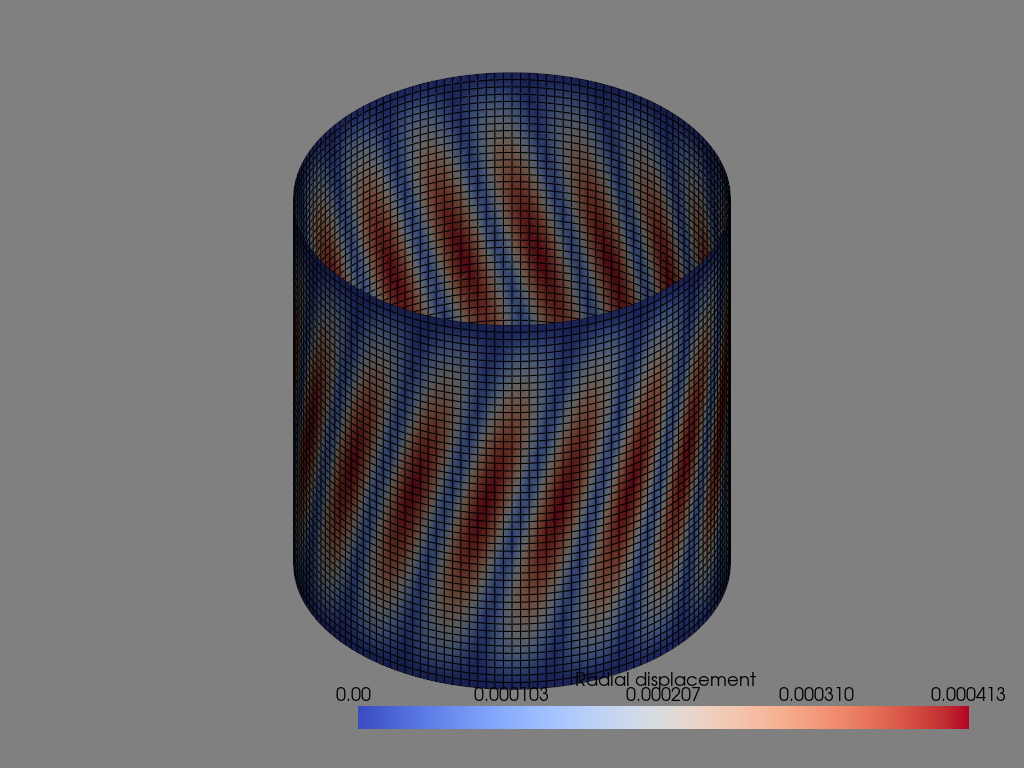

relative difference to Fig. 13 of Castro et al. 0.021595780960968147
ntheta 160
nlength 51
num_elements 8000
Nxy -636.6197723675814


elements created 1.7184998989105225
sparse KC0 and KG created


eigvals [38.17802953 38.17802953 38.39505825 38.39505825 39.35266953 39.35266953]
linear buckling analysis OK
Tcr = -9544.507381747153


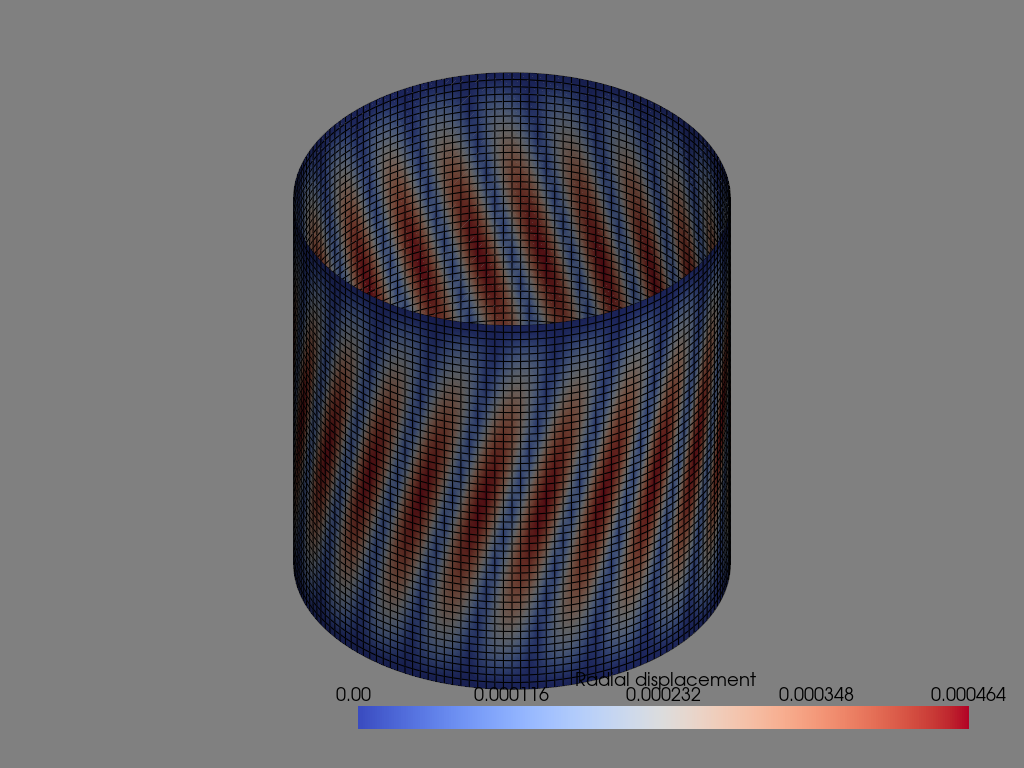

relative difference to Fig. 13 of Castro et al. 0.037446454537733986


In [3]:
test_linear_buckling_cylinder_Nxy(mode=0, plot_pyvista=True, refinement=2)

With `refinement=2` the torques are 2.2 % (Z11) and 3.7 % (Z33) above the
intercepts of Fig. 13, within grade B, and equal to the pre-determined 17162.8
and 9544.5 Nm. The load multipliers come in close pairs, which is why the
test requests six of them: with four, the eigensolver may miss members of these
clusters, which the verification of `linear_buckling` would report as an
error.

A second test of the same file,
`test_linear_buckling_cylinder_torsion_isotropic`, compares an isotropic
cylinder with simply supported edges ($R = 250$ mm, $L = 4 R$, $t = 4$ mm,
$\nu = 0.3$) with the classical critical shear stress of Batdorf, Stein and
Schildcrout (1947, p. 3),

$$
\tau_{cr} = k_s \frac{\pi^2 D}{L^2 t}, \qquad
k_s = 0.85 Z^{3/4}, \qquad
Z = \frac{L^2}{R t} \sqrt{1 - \nu^2}
$$

the straight-line approximation of their Galerkin solution, valid for $100 <
Z < 10 R^2/t^2$ (p. 4); with the correlation factor set to one it is Eq. (25)
of NASA SP-8007 (1968, Sec. 4.2.4, p. 11). Here $Z = 954$; the element
converges to 1.6 % below the formula, within the accuracy of the
straight-line fit itself, see the Notes of the test.

## References

- Batdorf, S. B., Stein, M. and Schildcrout, M., Critical stress of
  thin-walled cylinders in torsion, NACA TN 1344, 1947.
- Castro, S. G. P., Mittelstedt, C., Monteiro, F. A. C., Arbelo, M. A.,
  Ziegmann, G. and Degenhardt, R., Linear buckling predictions of
  unstiffened laminated composite cylinders and cones under various loading
  and boundary conditions using semi-analytical models, Composite
  Structures, 118, 303-315, 2014.
  https://doi.org/10.1016/j.compstruct.2014.07.037
- MacNeal, R. H. and Harder, R. L., A proposed standard set of problems to
  test finite element accuracy, Finite Elements in Analysis and Design,
  1(1), 3-20, 1985. https://doi.org/10.1016/0168-874X(85)90003-4
- NASA SP-8007, Buckling of thin-walled circular cylinders, 1965, revised
  1968.